# Aumentado de datos

In [1]:
import csv

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder

from utilidades import ejecutar_configuracion, desnormalizar, device, MEDIA, DESVIACION

torch.manual_seed(42)
print(f'Usando dispositivo: {device}')

Usando dispositivo: cpu


## Mejor configuración de la búsqueda manual (C8)

In [2]:
mejor_configuracion = {
    'tam_imagen': 128,
    'tam_lote': 64,
    'lr': 0.001,
    'filtros': (16, 32, 64),
    'neuronas_fc': (256, 128),
    'activacion': nn.LeakyReLU,
    'p_dropout': 0.5,
}

## Transformaciones con aumento de datos

In [3]:
tam_imagen = mejor_configuracion['tam_imagen']

transform_aumentado = transforms.Compose([
    transforms.Resize((tam_imagen, tam_imagen)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15, fill=178),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEDIA, DESVIACION)
])

transform_original = transforms.Compose([
    transforms.Resize((tam_imagen, tam_imagen)),
    transforms.ToTensor()
])

dataset_original = ImageFolder(root='datos/training', transform=transform_original)
dataset_aumentado = ImageFolder(root='datos/training', transform=transform_aumentado)
clases = dataset_original.classes

## Ejemplos de imágenes aumentadas

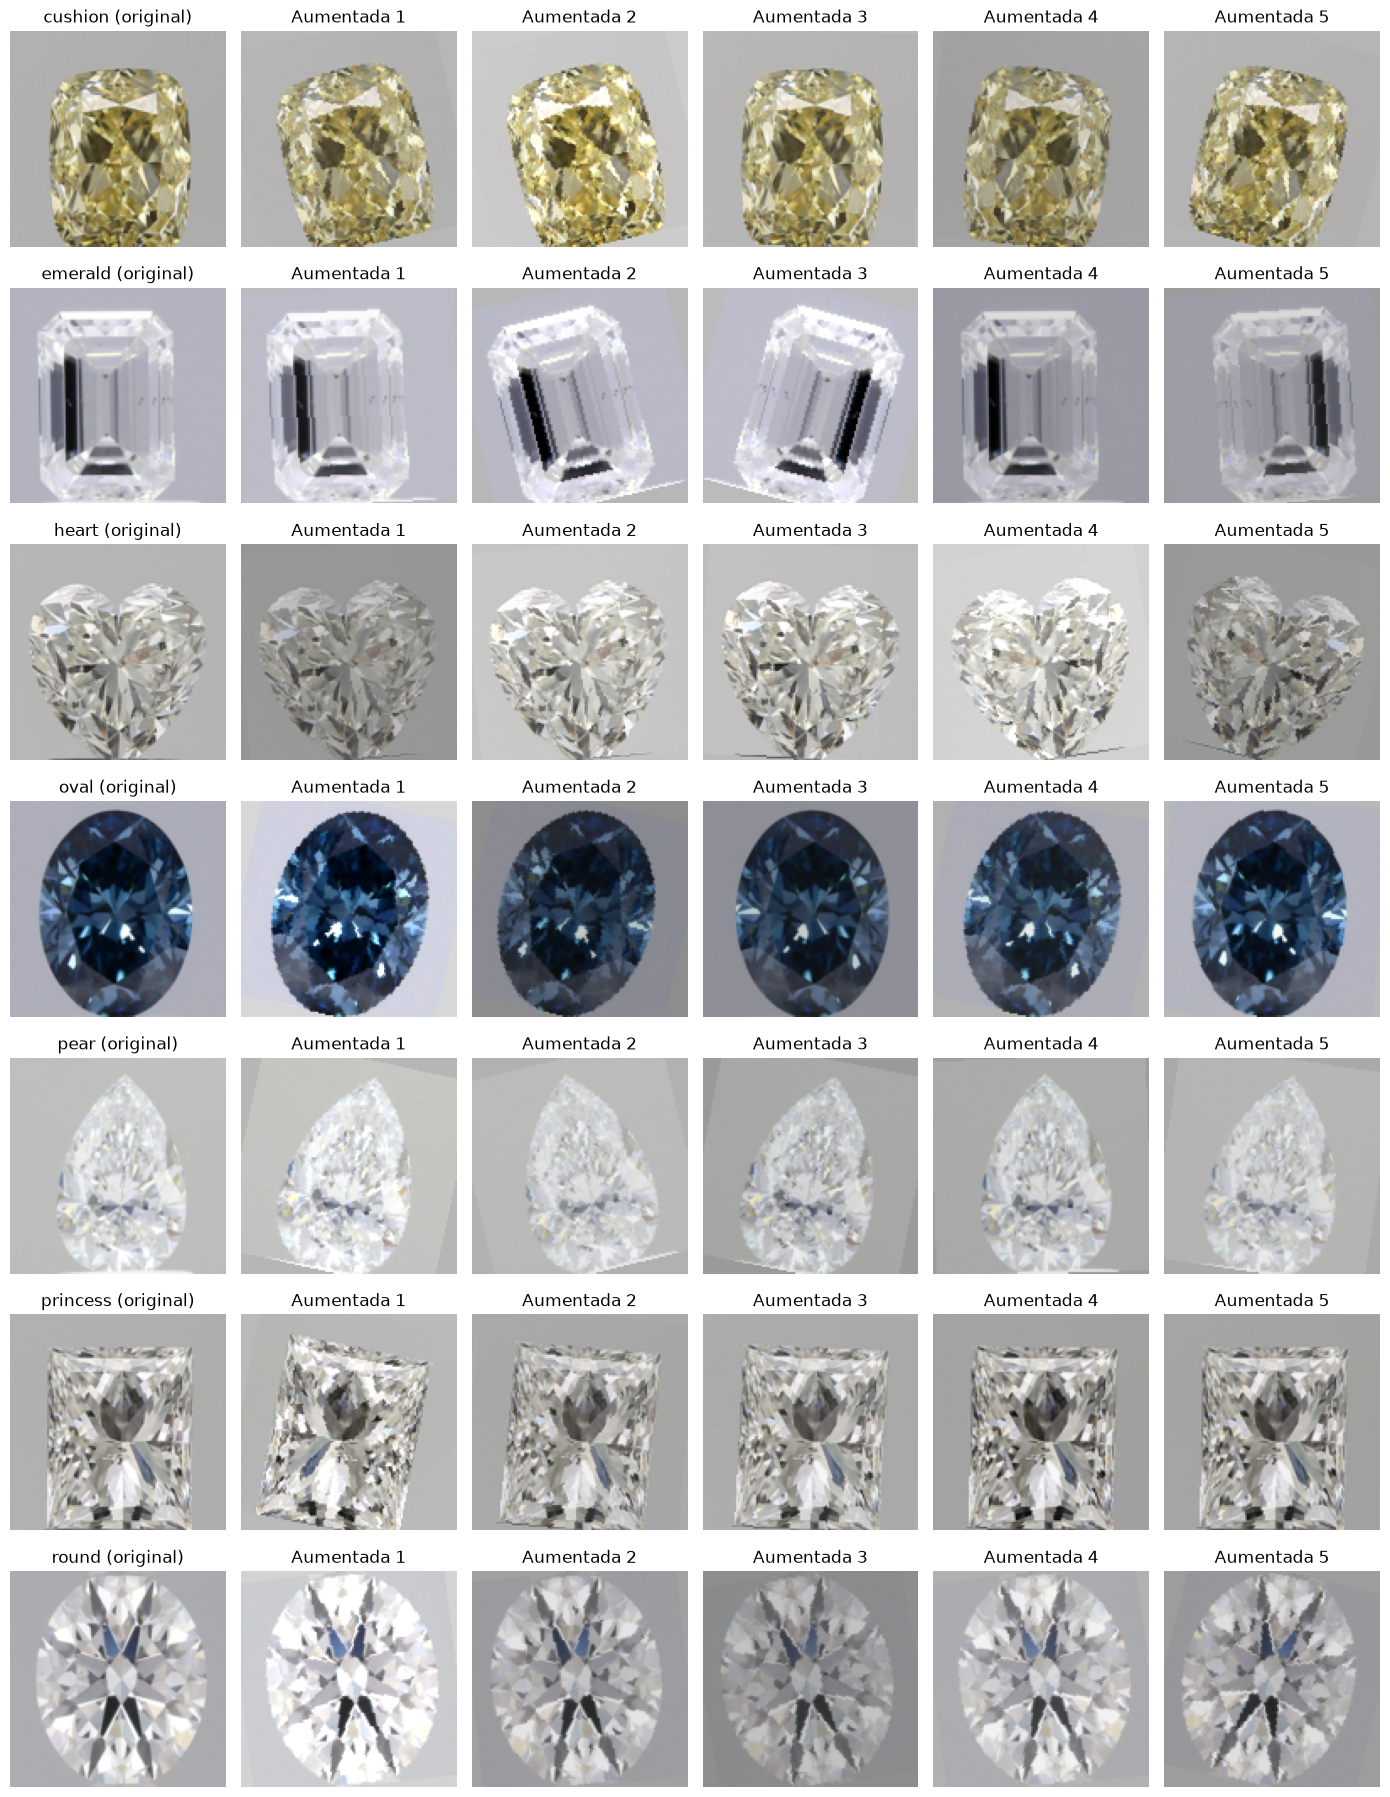

In [4]:
num_variantes = 5
columnas = num_variantes + 1

plt.figure(figsize=(14, 2.6 * len(clases)))
for indice_clase, clase in enumerate(clases):
    indice_imagen = dataset_original.targets.index(indice_clase)
    imagen_original, _ = dataset_original[indice_imagen]

    plt.subplot(len(clases), columnas, indice_clase * columnas + 1)
    plt.imshow(imagen_original.permute(1, 2, 0).numpy())
    plt.title(f'{clase} (original)')
    plt.axis('off')

    for variante in range(num_variantes):
        imagen_aumentada, _ = dataset_aumentado[indice_imagen]
        plt.subplot(len(clases), columnas, indice_clase * columnas + variante + 2)
        plt.imshow(desnormalizar(imagen_aumentada))
        plt.title(f'Aumentada {variante + 1}')
        plt.axis('off')
plt.tight_layout()
plt.savefig('graficas/ejemplos_aumentado.png', dpi=120)
plt.show()

## Volteo vertical en las clases con orientación: pear y heart

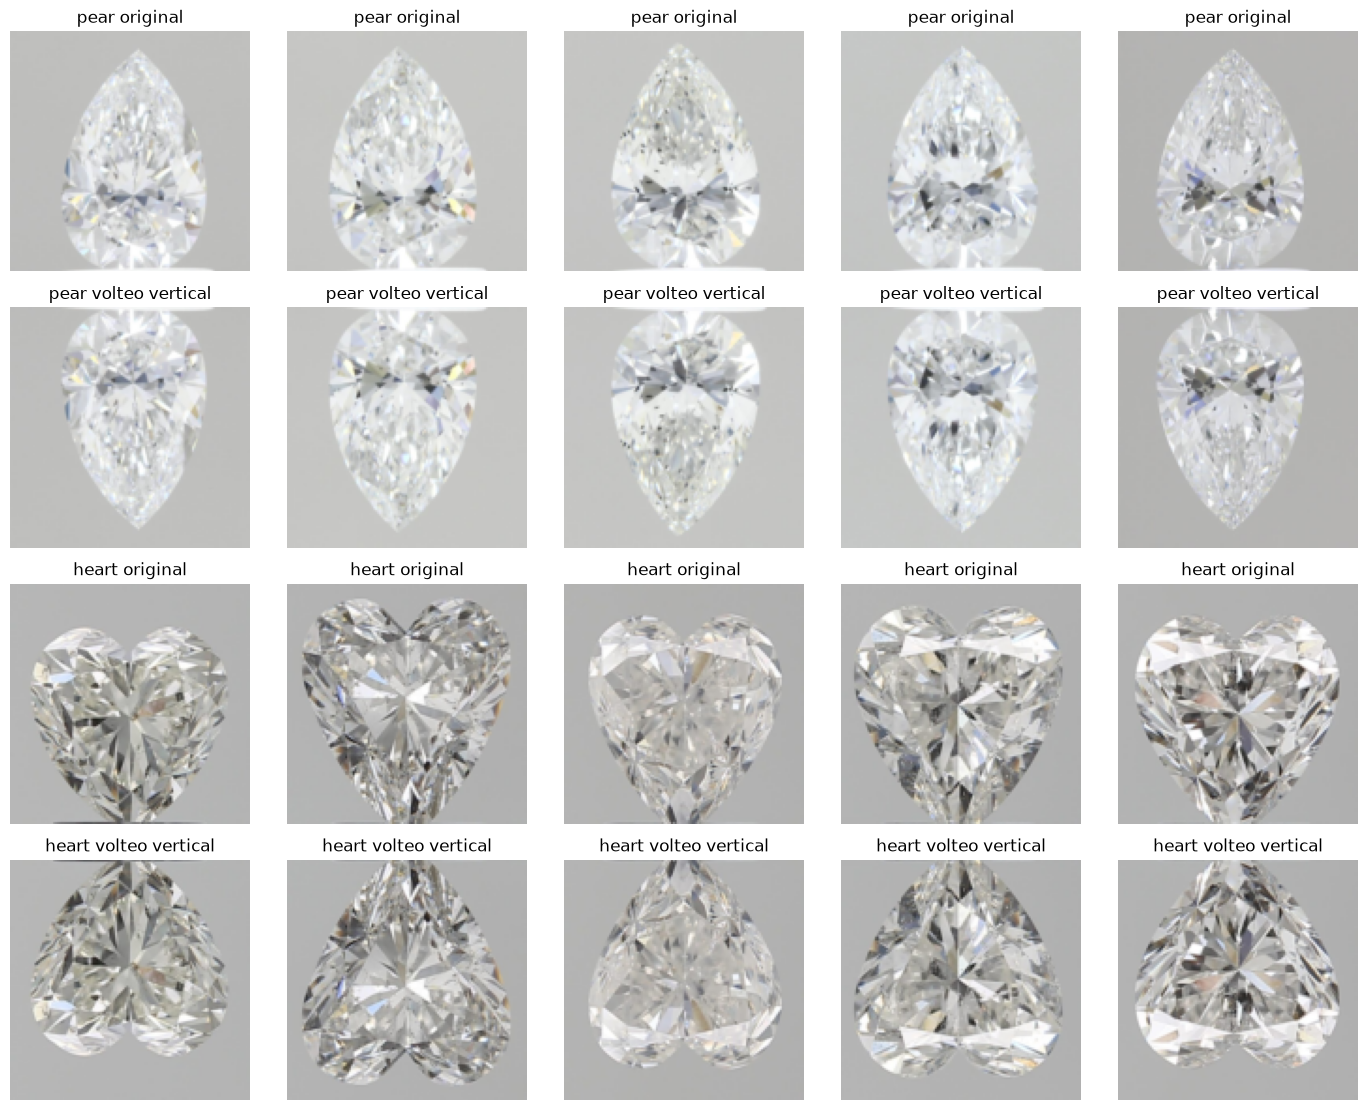

In [5]:
volteo_vertical = transforms.RandomVerticalFlip(p=1.0)
clases_orientadas = ['pear', 'heart']
num_ejemplos = 5

plt.figure(figsize=(14, 2.8 * 2 * len(clases_orientadas)))
for posicion_clase, clase in enumerate(clases_orientadas):
    indices_clase = [indice for indice, etiqueta in enumerate(dataset_original.targets)
                     if etiqueta == clases.index(clase)][:num_ejemplos]

    for posicion, indice_imagen in enumerate(indices_clase):
        imagen, _ = dataset_original[indice_imagen]
        fila_original = 2 * posicion_clase

        plt.subplot(2 * len(clases_orientadas), num_ejemplos, fila_original * num_ejemplos + posicion + 1)
        plt.imshow(imagen.permute(1, 2, 0).numpy())
        plt.title(f'{clase} original')
        plt.axis('off')

        plt.subplot(2 * len(clases_orientadas), num_ejemplos, (fila_original + 1) * num_ejemplos + posicion + 1)
        plt.imshow(volteo_vertical(imagen).permute(1, 2, 0).numpy())
        plt.title(f'{clase} volteo vertical')
        plt.axis('off')
plt.tight_layout()
plt.savefig('graficas/volteo_vertical.png', dpi=120)
plt.show()

## Entrenamiento con aumento de datos

Época [ 1/40] | Train Loss: 0.3535 | Train Acc: 0.8831 | Val Loss: 0.0347 | Val Acc: 0.9938 *
Época [ 2/40] | Train Loss: 0.0811 | Train Acc: 0.9778 | Val Loss: 0.0135 | Val Acc: 0.9963 *
Época [ 3/40] | Train Loss: 0.0693 | Train Acc: 0.9830 | Val Loss: 0.0197 | Val Acc: 0.9952 
Época [ 4/40] | Train Loss: 0.0575 | Train Acc: 0.9857 | Val Loss: 0.0136 | Val Acc: 0.9966 
Época [ 5/40] | Train Loss: 0.0480 | Train Acc: 0.9884 | Val Loss: 0.0140 | Val Acc: 0.9975 
Época [ 6/40] | Train Loss: 0.0427 | Train Acc: 0.9918 | Val Loss: 0.0078 | Val Acc: 0.9972 *
Época [ 7/40] | Train Loss: 0.0338 | Train Acc: 0.9923 | Val Loss: 0.0104 | Val Acc: 0.9975 
Época [ 8/40] | Train Loss: 0.0398 | Train Acc: 0.9909 | Val Loss: 0.0120 | Val Acc: 0.9969 
Época [ 9/40] | Train Loss: 0.0433 | Train Acc: 0.9908 | Val Loss: 0.0095 | Val Acc: 0.9978 
Época [10/40] | Train Loss: 0.0304 | Train Acc: 0.9932 | Val Loss: 0.0106 | Val Acc: 0.9975 
Época [11/40] | Train Loss: 0.0341 | Train Acc: 0.9928 | Val Loss: 

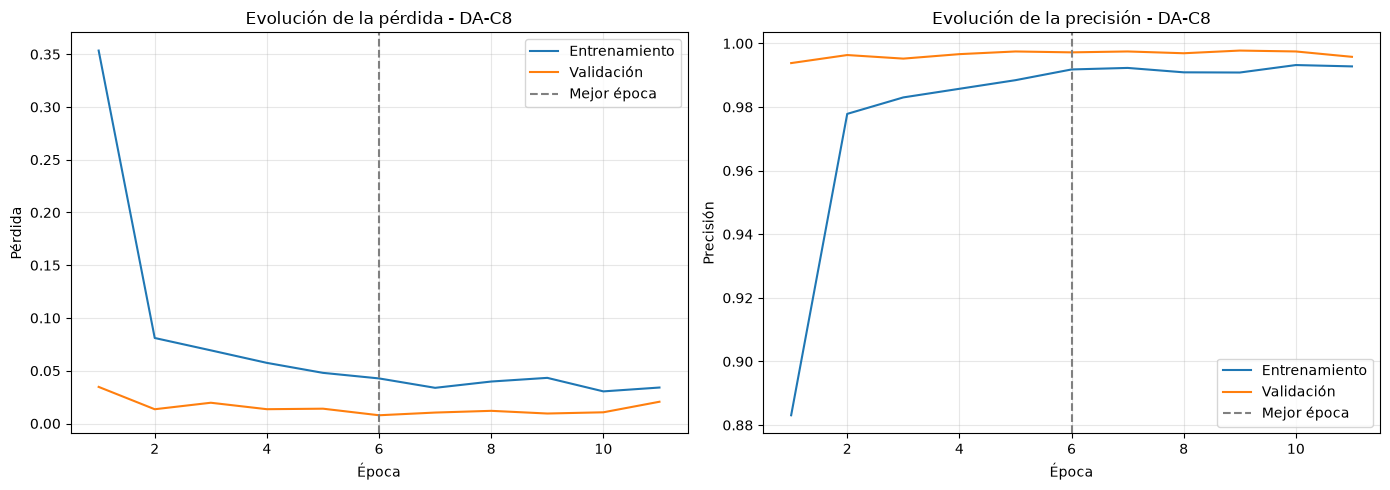

In [6]:
modelo_aumentado, historial_aumentado = ejecutar_configuracion('DA-C8', transform_train=transform_aumentado,
                                                              **mejor_configuracion)

## Comparación con la versión sin aumento

In [7]:
with open('resultados.csv', encoding='utf-8') as fichero:
    filas = {fila['configuracion']: fila for fila in csv.DictReader(fichero)}

print(f'{"Config":6s} | {"Épocas":6s} | {"Mejor":5s} | {"Loss train":10s} | {"Loss val":8s} | '
      f'{"Acc train":9s} | {"Acc val":7s} | {"Tiempo (s)":10s}')
for nombre in ['C8', 'DA-C8']:
    fila = filas[nombre]
    print(f'{nombre:6s} | {fila["epocas_entrenadas"]:6s} | {fila["mejor_epoca"]:5s} | {fila["perdida_train"]:10s} | '
          f'{fila["perdida_val"]:8s} | {fila["acc_train"]:9s} | {fila["acc_val"]:7s} | {fila["tiempo_segundos"]:10s}')

Config | Épocas | Mejor | Loss train | Loss val | Acc train | Acc val | Tiempo (s)
C8     | 17     | 12    | 0.015      | 0.0067   | 0.9969    | 0.9983  | 2818.1    
DA-C8  | 11     | 6     | 0.0427     | 0.0078   | 0.9918    | 0.9972  | 1785.2    


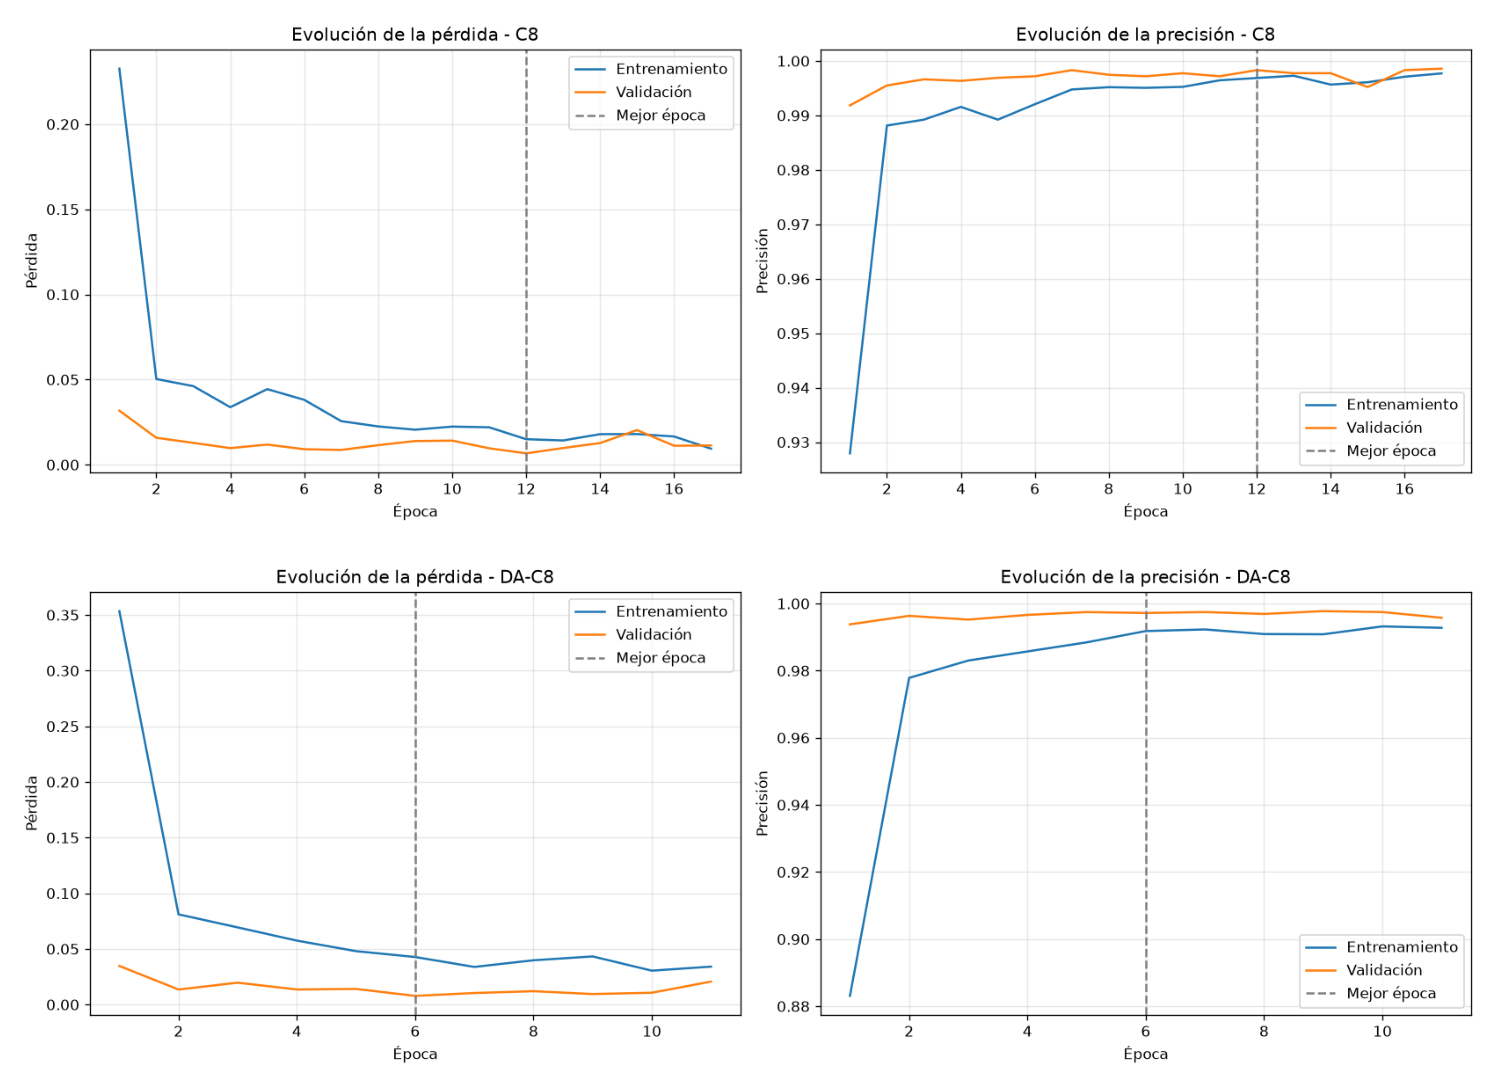

In [8]:
plt.figure(figsize=(16, 11))
for posicion, nombre in enumerate(['C8', 'DA-C8']):
    plt.subplot(2, 1, posicion + 1)
    plt.imshow(plt.imread(f'graficas/curvas_{nombre}.png'))
    plt.axis('off')
plt.tight_layout()
plt.show()